<a href="https://colab.research.google.com/github/kayanaazwalukmana-hub/Komputasi-Numerik/blob/main/Komputasi_Numerik_Bisection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Komputasi Numerik: Akar Persamaan Non Linear dengan Metode Bisection

Mencari akar dari persamaan **f(x) = x³ − 3x − 5 = 0** pada interval [2, 3]
dengan cara membagi dua interval berulang kali sampai cukup kecil.

**Prinsip:** jika f(a) dan f(b) berbeda tanda, pasti ada akar di antara a dan b
(teorema nilai antara). Titik tengah c = (a + b)/2 dicek tandanya, lalu separuh
interval yang tidak memuat akar dibuang. Ulangi sampai lebar interval atau nilai f(c) cukup kecil.

Run tiap cell berurutan dari atas.

### Langkah 1: Definisi fungsi

**Penjelasan cell:** persamaan yang dicari akarnya dibungkus dalam fungsi `f` supaya bisa dipanggil berkali-kali dengan nilai x berbeda. Dua baris `print` memperlihatkan tanda f di ujung interval: negatif di x = 2 dan positif di x = 3, artinya grafik memotong sumbu x di antaranya.

In [1]:
# Mendefinisikan fungsi f(x) = x^3 - 3x - 5; ganti rumusnya bila ingin soal lain
def f(x):
    # ** adalah operator pangkat di Python, jadi x**3 berarti x pangkat tiga
    return x**3 - 3*x - 5

# f(2) = 8 - 6 - 5 = -3  (negatif)
print("f(2) =", f(2))
# f(3) = 27 - 9 - 5 = 13  (positif)
print("f(3) =", f(3))

f(2) = -3
f(3) = 13


### Langkah 2: Parameter

**Penjelasan cell:** semua nilai yang bisa diatur dikumpulkan di satu tempat. `toleransi` menentukan seberapa teliti hasilnya, dan `iter_maks` adalah pengaman supaya perulangan tidak berjalan selamanya.

In [2]:
batas_kiri = 2.0     # ujung kiri interval pencarian (a)
batas_kanan = 3.0    # ujung kanan interval pencarian (b)
toleransi = 1e-5     # 1e-5 = 0.00001; iterasi berhenti jika sudah sekecil ini
iter_maks = 50       # batas jumlah iterasi sebagai pengaman

### Langkah 3: Cek syarat bisection

**Penjelasan cell:** metode ini hanya sah jika f di kedua ujung berbeda tanda. Hasil kali dua bilangan berbeda tanda pasti negatif, sehingga cukup diperiksa dengan satu perkalian. Jika syarat tidak terpenuhi, program dihentikan dengan pesan kesalahan.

In [3]:
# Jika hasil kali >= 0, tandanya sama (atau ada yang nol) sehingga akar tidak dijamin ada
if f(batas_kiri) * f(batas_kanan) >= 0:
    # raise menghentikan program dan menampilkan pesan error ini
    raise ValueError("f(kiri) dan f(kanan) harus berbeda tanda")

# Baris ini hanya tercetak jika syarat di atas lolos
print("Syarat terpenuhi: ada akar di antara", batas_kiri, "dan", batas_kanan)

Syarat terpenuhi: ada akar di antara 2.0 dan 3.0


### Langkah 4: Iterasi bisection

**Penjelasan cell:** inti metode ada di sini. Setiap putaran menghitung titik tengah, mencetak barisnya ke tabel, mengecek apakah sudah cukup akurat, lalu mempersempit interval menjadi separuhnya. Bagian yang berisi akar dipertahankan, bagian lain dibuang.

In [4]:
# Salin batas awal ke variabel kerja agar batas_kiri dan batas_kanan asli tidak berubah
kiri, kanan = batas_kiri, batas_kanan

# Cetak kepala tabel; <5 dan <12 artinya rata kiri dengan lebar kolom tertentu
print(f"{'iter':<5}{'kiri':<12}{'kanan':<12}{'tengah':<12}{'f(tengah)':<14}")

# Ulangi dari iterasi 1 sampai iter_maks (angka akhir range tidak ikut, jadi ditambah 1)
for iterasi in range(1, iter_maks + 1):
    tengah = (kiri + kanan) / 2    # titik tengah interval saat ini
    # Cetak satu baris tabel: nilai-nilai dibulatkan 6 angka di belakang koma
    print(f"{iterasi:<5}{kiri:<12.6f}{kanan:<12.6f}{tengah:<12.6f}{f(tengah):<14.6f}")

    # Berhenti jika f(tengah) sudah hampir nol ATAU setengah lebar interval sudah cukup kecil
    if abs(f(tengah)) < toleransi or (kanan - kiri) / 2 < toleransi:
        break    # keluar dari perulangan; nilai 'tengah' terakhir menjadi akar

    # Jika tanda f(kiri) dan f(tengah) berbeda, akar ada di separuh kiri
    if f(kiri) * f(tengah) < 0:
        kanan = tengah    # buang separuh kanan: batas kanan pindah ke titik tengah
    else:
        kiri = tengah     # sebaliknya, akar di separuh kanan: batas kiri pindah ke titik tengah

iter kiri        kanan       tengah      f(tengah)     
1    2.000000    3.000000    2.500000    3.125000      
2    2.000000    2.500000    2.250000    -0.359375     
3    2.250000    2.500000    2.375000    1.271484      
4    2.250000    2.375000    2.312500    0.428955      
5    2.250000    2.312500    2.281250    0.028107      
6    2.250000    2.281250    2.265625    -0.167294     
7    2.265625    2.281250    2.273438    -0.070010     
8    2.273438    2.281250    2.277344    -0.021056     
9    2.277344    2.281250    2.279297    0.003499      
10   2.277344    2.279297    2.278320    -0.008785     
11   2.278320    2.279297    2.278809    -0.002644     
12   2.278809    2.279297    2.279053    0.000427      
13   2.278809    2.279053    2.278931    -0.001109     
14   2.278931    2.279053    2.278992    -0.000341     
15   2.278992    2.279053    2.279022    0.000043      
16   2.278992    2.279022    2.279007    -0.000149     
17   2.279007    2.279022    2.279015    -0.0000

### Langkah 5: Hasil akhir

**Penjelasan cell:** titik tengah terakhir dari perulangan diambil sebagai akar hampiran. Nilai f di akar ditampilkan untuk memastikan hasilnya mendekati nol, dan jumlah iterasi menunjukkan seberapa cepat metode ini konvergen.

In [5]:
akar = tengah    # titik tengah pada iterasi terakhir adalah akar hampiran
print(f"Akar hampiran : {akar:.6f}")        # tampilkan 6 angka di belakang koma
print(f"f(akar)       : {f(akar):.8f}")     # seharusnya sangat dekat dengan 0
print(f"Jumlah iterasi: {iterasi}")         # banyaknya putaran yang dipakai

Akar hampiran : 2.279015
f(akar)       : -0.00005283
Jumlah iterasi: 17


### Langkah 6: Grafik fungsi

**Penjelasan cell:** grafik memperlihatkan kurva f(x) pada interval pencarian dan titik merah di posisi akar yang ditemukan. Titik itu seharusnya tepat di perpotongan kurva dengan garis y = 0.

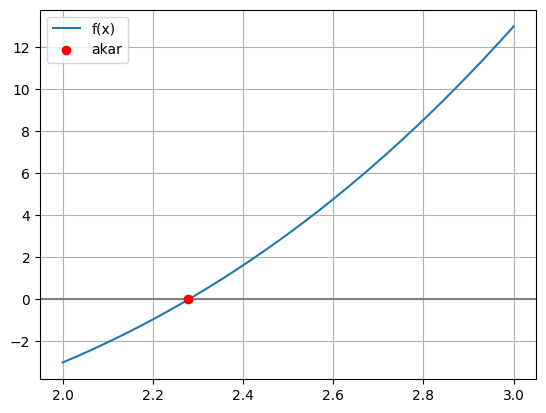

In [6]:
# Mengimpor modul matplotlib untuk menggambar grafik
import matplotlib.pyplot as plt

# Membuat 201 titik x yang tersebar rata dari batas_kiri sampai batas_kanan
xs = [batas_kiri + i * (batas_kanan - batas_kiri) / 200 for i in range(201)]
# Menghitung f untuk tiap titik x tadi
ys = [f(v) for v in xs]

plt.plot(xs, ys, label="f(x)")                                      # gambar kurva f(x)
plt.axhline(0, color="gray")                                        # garis horizontal y = 0 (sumbu x)
plt.scatter([akar], [0], color="red", zorder=3, label="akar")       # titik merah di posisi akar
plt.legend()                                                        # tampilkan keterangan label
plt.grid(True)                                                      # tambahkan garis bantu
plt.show()                                                          # tampilkan grafik